CONTOH DATA


,Program_Studi,Semester,Jumlah_Tagihan,Riwayat_Terlambat,Terlambat
0,Teknik Sipil,1,3500000,1,1
1,Teknik Elektro,1,3000000,0,0
2,Informatika,3,4000000,3,0
3,Teknik Sipil,6,2500000,3,0
4,Teknik Sipil,2,3000000,1,0



JUMLAH STATUS PEMBAYARAN
Terlambat
Tepat Waktu    229
Terlambat       71
Name: count, dtype: int64


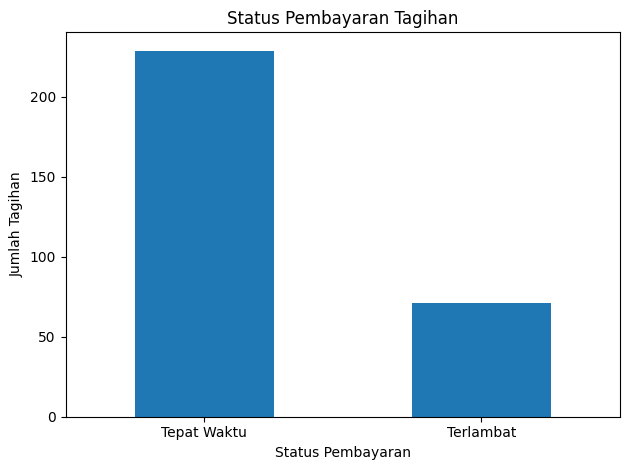


HASIL EVALUASI
Accuracy: 0.60
Precision: 0.29
Recall: 0.50
F1-Score: 0.37


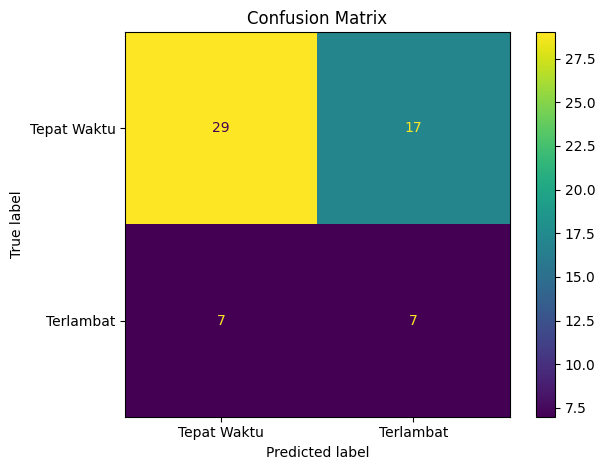


HASIL PREDIKSI TAGIHAN BARU


,Program_Studi,Semester,Jumlah_Tagihan,Riwayat_Terlambat,Prediksi,Peluang Terlambat (%)
0,Informatika,5,2500000,0,Risiko Lebih Rendah,45.9
1,Teknik Sipil,2,4000000,3,Berisiko Terlambat,100.0
2,Sistem Informasi,7,2000000,1,Berisiko Terlambat,65.8



KESIMPULAN
Model digunakan untuk memperkirakan risiko keterlambatan.
Hasil prediksi perlu diperiksa sebelum dijadikan dasar tindakan.
Data yang digunakan merupakan data simulasi.


In [1]:

# IMPLEMENTASI ANALISIS DAN PREDIKSI KETERLAMBATAN PEMBAYARAN
# Metode: Decision Tree
# Dataset: Data simulasi

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. MEMBUAT DATA SIMULASI

np.random.seed(42)
n = 300

data = pd.DataFrame({
    "Program_Studi": np.random.choice(
        ["Informatika", "Sistem Informasi",
         "Teknik Sipil", "Teknik Elektro"], n
    ),
    "Semester": np.random.randint(1, 9, n),
    "Jumlah_Tagihan": np.random.choice(
        [1500000, 2000000, 2500000,
         3000000, 3500000, 4000000], n
    ),
    "Riwayat_Terlambat": np.random.choice(
        [0, 1, 2, 3], n, p=[0.55, 0.25, 0.15, 0.05]
    )
})

# Membuat label keterlambatan simulasi
logit = (
    -2
    + 0.75 * data["Riwayat_Terlambat"]
    + (data["Jumlah_Tagihan"] - 2500000) / 2500000 * 0.35
    + (data["Semester"] <= 2) * 0.15
)

probabilitas = 1 / (1 + np.exp(-logit))

data["Terlambat"] = np.random.binomial(1, probabilitas)

print("CONTOH DATA")
display(data.head())

# 2. ANALISIS DESKRIPTIF

print("\nJUMLAH STATUS PEMBAYARAN")
print(data["Terlambat"].value_counts().rename({
    0: "Tepat Waktu",
    1: "Terlambat"
}))

data["Terlambat"].value_counts().sort_index().rename({
    0: "Tepat Waktu",
    1: "Terlambat"
}).plot(kind="bar")

plt.title("Status Pembayaran Tagihan")
plt.xlabel("Status Pembayaran")
plt.ylabel("Jumlah Tagihan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. MENYIAPKAN DATA

X = data[
    ["Program_Studi", "Semester",
     "Jumlah_Tagihan", "Riwayat_Terlambat"]
]

y = data["Terlambat"]

preprocessor = ColumnTransformer([
    (
        "kategori",
        OneHotEncoder(handle_unknown="ignore"),
        ["Program_Studi"]
    )
], remainder="passthrough")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. MEMBUAT DAN MELATIH MODEL

model = Pipeline([
    ("preprocessing", preprocessor),
    ("decision_tree", DecisionTreeClassifier(
        max_depth=4,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

# 5. EVALUASI MODEL

prediksi = model.predict(X_test)

metrik = {
    "Accuracy": accuracy_score(y_test, prediksi),
    "Precision": precision_score(
        y_test, prediksi, zero_division=0
    ),
    "Recall": recall_score(
        y_test, prediksi, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, prediksi, zero_division=0
    )
}

print("\nHASIL EVALUASI")
for nama, nilai in metrik.items():
    print(f"{nama}: {nilai:.2f}")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediksi,
    display_labels=["Tepat Waktu", "Terlambat"]
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# 6. PREDIKSI TAGIHAN BARU

tagihan_baru = pd.DataFrame({
    "Program_Studi": [
        "Informatika",
        "Teknik Sipil",
        "Sistem Informasi"
    ],
    "Semester": [5, 2, 7],
    "Jumlah_Tagihan": [2500000, 4000000, 2000000],
    "Riwayat_Terlambat": [0, 3, 1]
})

hasil = model.predict(tagihan_baru)
peluang = model.predict_proba(tagihan_baru)[:, 1]

tagihan_baru["Prediksi"] = np.where(
    hasil == 1, "Berisiko Terlambat", "Risiko Lebih Rendah"
)

tagihan_baru["Peluang Terlambat (%)"] = (
    peluang * 100
).round(1)

print("\nHASIL PREDIKSI TAGIHAN BARU")
display(tagihan_baru)

# 7. KESIMPULAN

print("\nKESIMPULAN")
print("Model digunakan untuk memperkirakan risiko keterlambatan.")
print("Hasil prediksi perlu diperiksa sebelum dijadikan dasar tindakan.")
print("Data yang digunakan merupakan data simulasi.")
